# 강의실 사람 탐지 파인튜닝 결과

전체 450장 중 학습 316장, 검증 88장, 테스트 46장. 저장된 지표로 그래프를 재현한다.

## 테스트 성능 비교

MLflow classroom-yolo-detection의 before-test-271c1006 및 after-test-271c1006. 동일한 테스트 이미지 46장에서 Student와 with-student 정답 박스를 하나의 사람 탐지 클래스로 묶었다. 사전학습 모델은 COCO person 예측만 사용했다.

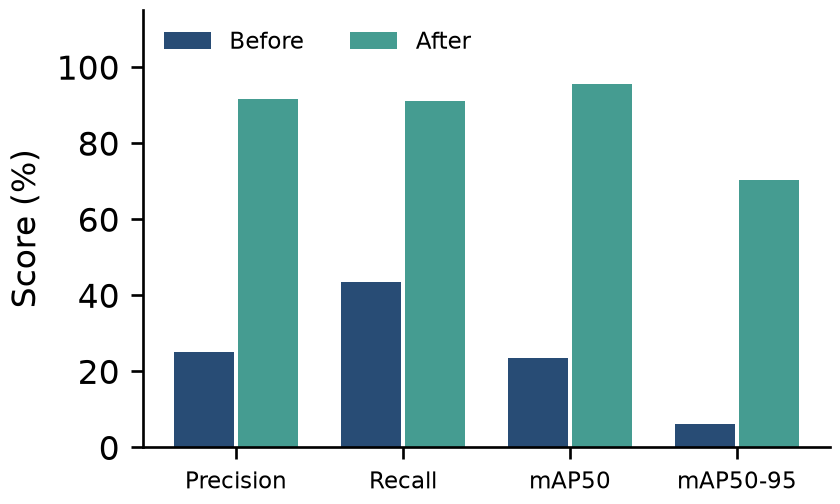

In [1]:
import matplotlib.pyplot as plt
scores = {'before': {'precision': 0.24973854212836158, 'recall': 0.43512322988283114, 'map50': 0.23609341910337883, 'map50_95': 0.06142040761489441, 'inference_ms_per_image': 18.59493391163161}, 'after': {'precision': 0.9146853923310204, 'recall': 0.9109639991116408, 'map50': 0.9551308889832201, 'map50_95': 0.7026189207579531, 'inference_ms_per_image': 17.76932425412309}}
keys = ['precision', 'recall', 'map50', 'map50_95']
fig, ax = plt.subplots(figsize=(3.5, 2.1), layout='constrained')
for stage, offset, color in [('before', -.19, '#284C75'), ('after', .19, '#459C91')]:
    ax.bar([i+offset for i in range(4)], [100*scores[stage][key] for key in keys],
           .36, label=stage.title(), color=color)
ax.set_xticks(range(4), ['Precision', 'Recall', 'mAP50', 'mAP50-95'], fontsize=7)
ax.set_ylabel('Score (%)')
ax.set_ylim(0, 115)
ax.legend(loc='upper left', ncols=2, fontsize=7, frameon=False)
plt.show()


## 검증 성능과 체크포인트 선택

출처는 fine_tuning/runs/yolo/classroom-person/results.csv이다. 이 그래프의 검증 지표는 원래 두 클래스 기준이다.

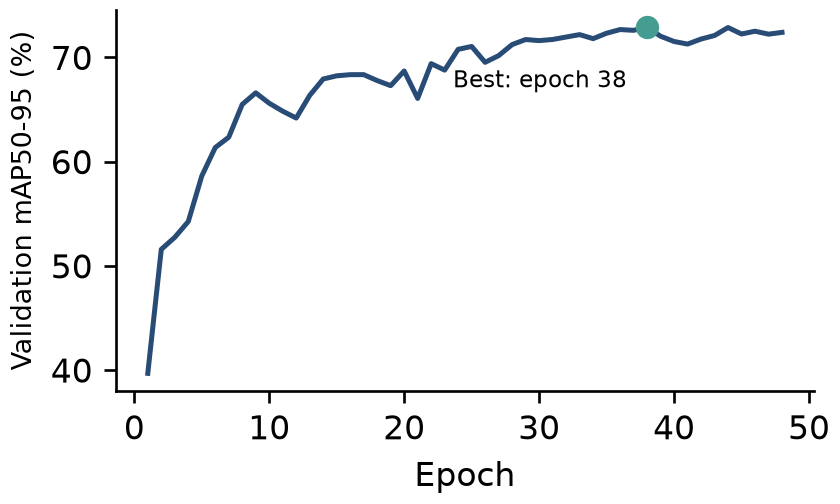

In [2]:
epochs = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48]
val_map = [39.674, 51.571, 52.728, 54.243, 58.605, 61.339, 62.333, 65.482, 66.59, 65.594, 64.828, 64.174, 66.346, 67.919, 68.224, 68.334, 68.338, 67.768, 67.279, 68.687, 66.058, 69.391, 68.771, 70.766, 71.041, 69.519, 70.161, 71.221, 71.706, 71.602, 71.711, 71.945, 72.178, 71.791, 72.31, 72.662, 72.589, 72.879, 72.024, 71.518, 71.27, 71.753, 72.092, 72.858, 72.237, 72.504, 72.221, 72.392]
fig, ax = plt.subplots(figsize=(3.5, 2.1), layout='constrained')
ax.plot(epochs, val_map, color='#284C75')
best = max(range(len(val_map)), key=val_map.__getitem__)
ax.scatter(epochs[best], val_map[best], color='#459C91', zorder=3)
ax.annotate('Best: epoch 38', (epochs[best], val_map[best]),
            xytext=(-6,-18), textcoords='offset points', ha='right', fontsize=7)
ax.set_xlabel('Epoch')
ax.set_ylabel('Validation mAP50-95 (%)', fontsize=8)
plt.show()


## 해석

테스트 mAP50–95는 6.14%에서 70.26%로 상승했다. 영상 추적 ID 유지와 실제 처리 FPS는 별도의 영상 평가가 필요하다.